# Un gen prestado de un liquen: ¿cuánto grano más da el trigo en sequía?

**En un año de sequía moderada, un cultivo suele perder entre 30 % y 40 % de su producción**, según el paper. Un equipo tomó un gen de un hongo que vive en líquenes de ambientes extremos y lo metió en trigo, arroz y maíz. ¿Cuánto rinde el trigo con ese gen frente al mismo trigo sin él? Y, sobre todo, ¿deja de dolerle la sequía?

**Paper:** Du et al. (2026). *An extremophile transgene improves drought resistance and yield in cereals*. **Nature**.
**DOI:** [10.1038/s41586-026-11151-w](https://doi.org/10.1038/s41586-026-11151-w)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-25-gen-extremofilo-sequia-cereales/notebook.ipynb)

**Video:** Pendiente

El gen se llama *EpTFIIAγ* y viene de *Endocarpon pusillum*, el hongo de un liquen que aguanta la sequía extrema. Codifica un factor de transcripción (una proteína que enciende y apaga otros genes) que se activa con el estrés osmótico, la falta de agua dentro de la célula.

El equipo lo expresó en cinco variedades (cultivares) de trigo y sembró cada línea con el gen junto a su variedad original sin el gen, el control (en los datos aparece como `silvestre`, del inglés *wild type*). Lo hicieron tres años seguidos, de 2023 a 2025, en Yangling (China), con dos tratamientos: riego completo y déficit hídrico (bajo un techo que bloquea la lluvia y con cerca del 30 % del agua del riego completo). Cada línea ocupó 4 parcelas por tratamiento. También probaron arroz y maíz en otros campos de China.

Vamos a abrir los datos crudos que el paper publica junto a sus figuras (la *Source Data*): rendimiento por parcela y por planta de los cinco cultivares, los componentes del rendimiento y las plantas de arroz y maíz.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
CULTIVAR = 'XZ9104'            # celda experimental: Fielder, JM22, XN511, XN979 o XZ9104
CONDICION = 'deficit_hidrico'  # celda experimental: 'deficit_hidrico' o 'riego_completo'
COLOR_DATOS = '#2563EB'        # con el gen
COLOR_ALERTA = '#DC2626'       # control sin el gen
COLOR_REFERENCIA = '#D97706'
COLOR_SEC = '#059669'          # riego completo
COLOR_GRIS = '#BBBBBB'
FUENTE = 'Fuente: Du et al. (2026), Nature | Datos: Source Data del paper (MOESM20, MOESM25, MOESM36)'

import os, re, math, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-11-25-gen-extremofilo-sequia-cereales'
ARCHIVOS = ['trigo_ganancia_cultivar_anio.csv', 'trigo_perdida_por_sequia.csv', 'trigo_lineas_efecto.csv',
            'trigo_parcelas.csv', 'trigo_rasgos_resumen.csv', 'trigo_plantas.csv',
            'trigo_sitios_aridos_2025.csv', 'arroz_maiz_plantas.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles, signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(\d)e\+?(-?)0*(\d+)', r'\1×10^\2\3', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# ── Carga ──
gan = pd.read_csv('datos/trigo_ganancia_cultivar_anio.csv')   # ganancia % por cultivar-año (media de líneas / control)
perd = pd.read_csv('datos/trigo_perdida_por_sequia.csv')       # caída por sequía, control vs con gen (kg/parcela)
lin = pd.read_csv('datos/trigo_lineas_efecto.csv')             # d, Welch y Mann-Whitney por línea (n=4 vs 4 parcelas)
parc = pd.read_csv('datos/trigo_parcelas.csv')                 # rendimiento por parcela (kg)
ras = pd.read_csv('datos/trigo_rasgos_resumen.csv')            # media/de/n por rasgo x línea x año x riego
plant = pd.read_csv('datos/trigo_plantas.csv')                 # rendimiento por planta (g), Yangling
arid = pd.read_csv('datos/trigo_sitios_aridos_2025.csv')       # 3 sitios áridos 2025, por planta (g)
am = pd.read_csv('datos/arroz_maiz_plantas.csv')               # arroz y maíz, por planta (g)

ETQ = {'deficit_hidrico': 'déficit hídrico', 'riego_completo': 'riego completo'}
pr(f'Trigo (Yangling): {parc.cultivar.nunique()} cultivares × {parc.anio.nunique()} años '
   f'({parc.anio.min()}-{parc.anio.max()}) × 2 riegos')
pr(f'  Parcelas: {len(parc)} | pares línea con el gen × año, por riego: '
   f'{len(lin[lin.condicion == "deficit_hidrico"])} | parcelas por línea: '
   f'{parc.groupby(["anio", "cultivar", "condicion", "linea"]).size().unique().tolist()}')
pr(f'  Plantas medidas: {len(plant):_}')
pr(f'Sitios áridos 2025: {arid.sitio.nunique()} sitios, {len(arid):_} plantas')
pr(f'Arroz y maíz: {len(am)} plantas en {am.groupby(["cultivo", "sitio", "anio"]).ngroups} combinaciones sitio-año')

Trigo (Yangling): 5 cultivares × 3 años (2023-2025) × 2 riegos
  Parcelas: 384 | pares línea con el gen × año, por riego: 33 | parcelas por línea: [4]
  Plantas medidas: 8.796
Sitios áridos 2025: 3 sitios, 2.700 plantas
Arroz y maíz: 744 plantas en 5 combinaciones sitio-año


Aquí está.

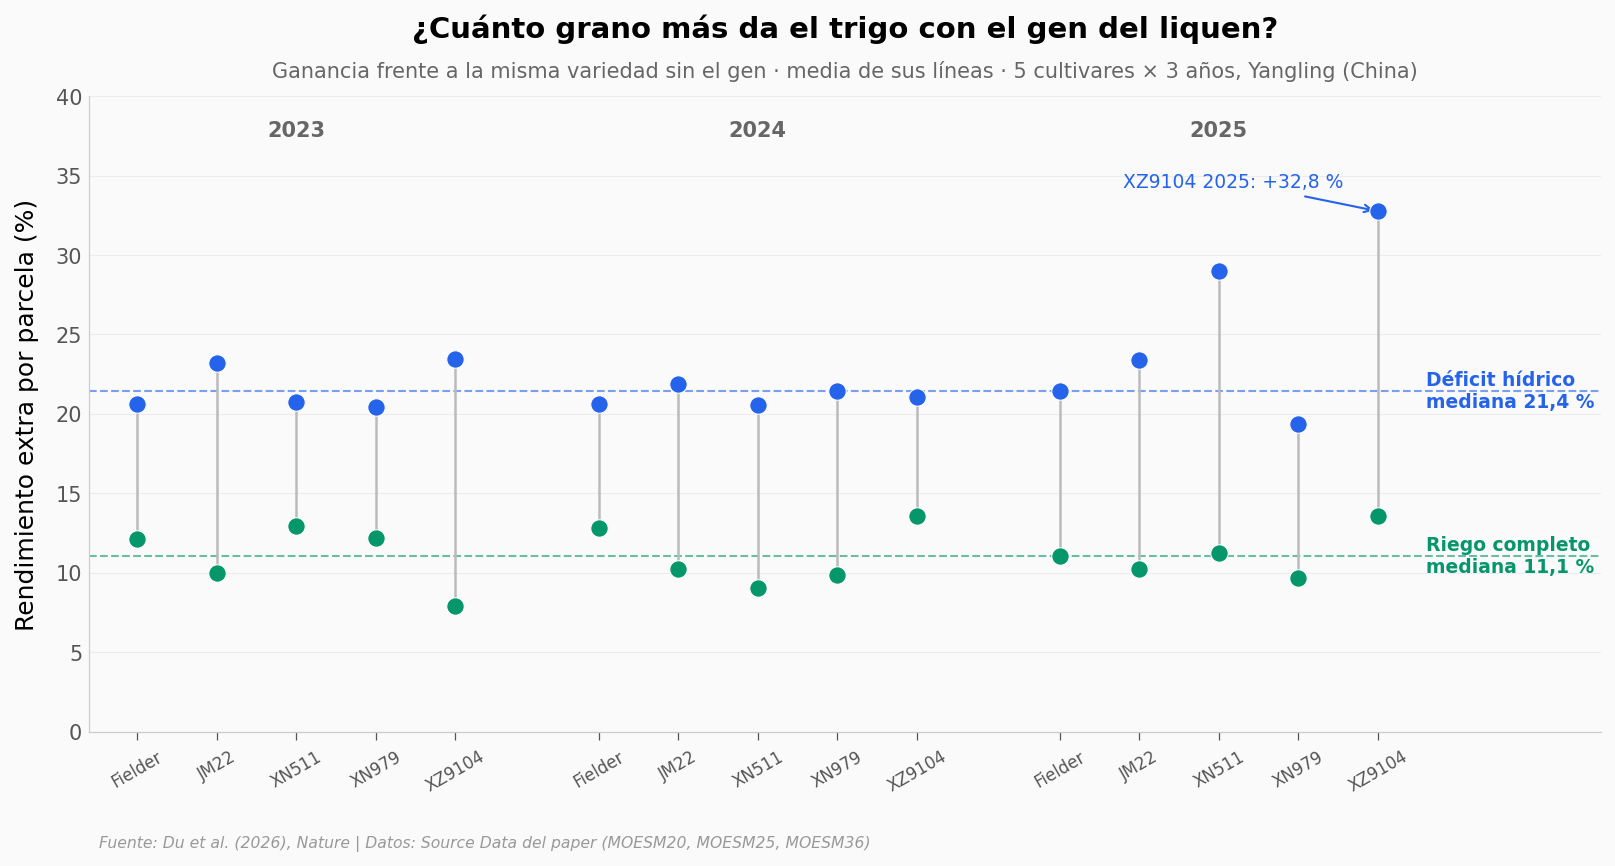

déficit hídrico: rango 19,37–32,76 % (mín XN979 2025, máx XZ9104 2025) | mediana 21,4 % | IQR 20,6–23,3 % | n = 15 cultivar-año
   kg/parcela: control mediana 4,11 | extra mediana +0,88 kg (rango +0,69 a +1,83)
riego completo: rango 7,88–13,55 % (mín XZ9104 2023, máx XZ9104 2025) | mediana 11,1 % | IQR 9,9–12,5 % | n = 15 cultivar-año
   kg/parcela: control mediana 6,88 | extra mediana +0,72 kg (rango +0,52 a +1,04)
déficit hídrico: líneas por encima del control 33/33 | Welch p < 0,05 en 33/33 | Mann-Whitney p < 0,05 en 32/33 (p más bajo observado: 0,029; el mínimo que permite el test con 4 frente a 4 es 0,029) | d mediana 4,4 (rango 2,2–10,2)
riego completo: líneas por encima del control 33/33 | Welch p < 0,05 en 33/33 | Mann-Whitney p < 0,05 en 31/33 (p más bajo observado: 0,029; el mínimo que permite el test con 4 frente a 4 es 0,029) | d mediana 3,3 (rango 2,2–6,4)
Cultivar-año con más ganancia en déficit que en riego: 15/15


In [2]:
g = gan.copy()
g['dif_kg'] = g.media_transgenicas_kg - g.media_silvestre_kg
orden = g[['anio', 'cultivar']].drop_duplicates().sort_values(['anio', 'cultivar']).reset_index(drop=True)
orden['x'] = orden.index + orden.anio.map({2023: 0, 2024: 1, 2025: 2}) * 0.8
g = g.merge(orden, on=['anio', 'cultivar'])
d_ = g[g.condicion == 'deficit_hidrico'].sort_values('x')
r_ = g[g.condicion == 'riego_completo'].sort_values('x')

fig, ax = plt.subplots(figsize=(13, 5.5))
for xi, a, b in zip(d_.x, d_.ganancia_pct, r_.ganancia_pct):
    ax.plot([xi, xi], [b, a], color=COLOR_GRIS, lw=1.2, zorder=2)
ax.scatter(d_.x, d_.ganancia_pct, color=COLOR_DATOS, s=70, edgecolors='white', linewidths=0.5, zorder=5)
ax.scatter(r_.x, r_.ganancia_pct, color=COLOR_SEC, s=70, edgecolors='white', linewidths=0.5, zorder=5)
for serie, col in [(d_, COLOR_DATOS), (r_, COLOR_SEC)]:
    ax.axhline(serie.ganancia_pct.median(), color=col, lw=1, ls='--', alpha=0.6, zorder=1)
xr = orden.x.max() + 0.6
ax.text(xr, d_.ganancia_pct.median(), f'Déficit hídrico\nmediana {es(f"{d_.ganancia_pct.median():.1f}")} %',
        color=COLOR_DATOS, fontsize=9, fontweight='bold', va='center')
ax.text(xr, r_.ganancia_pct.median(), f'Riego completo\nmediana {es(f"{r_.ganancia_pct.median():.1f}")} %',
        color=COLOR_SEC, fontsize=9, fontweight='bold', va='center')
top = d_.loc[d_.ganancia_pct.idxmax()]
ax.annotate(f'{top.cultivar} {top.anio}: +{es(f"{top.ganancia_pct:.1f}")} %', xy=(top.x, top.ganancia_pct),
            xytext=(top.x - 3.2, top.ganancia_pct + 1.5), fontsize=9, color=COLOR_DATOS,
            arrowprops=dict(arrowstyle='->', color=COLOR_DATOS, lw=1))
for anio, sub in orden.groupby('anio'):
    ax.text(sub.x.mean(), 37.5, str(anio), ha='center', fontsize=10, fontweight='bold', color='#666666')
ax.set_xticks(orden.x)
ax.set_xticklabels(orden.cultivar, fontsize=8, rotation=30)
ax.set_xlim(-0.6, xr + 2.2)
ax.set_ylim(0, 40)
ax.set_ylabel('Rendimiento extra por parcela (%)')
ax.yaxis.set_major_formatter(COMA)
ax.set_title('¿Cuánto grano más da el trigo con el gen del liquen?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Ganancia frente a la misma variedad sin el gen · media de sus líneas · 5 cultivares × 3 años, Yangling (China)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/ganancia_trigo_cultivar_anio.png', dpi=200, bbox_inches='tight')
plt.show()

for c, s in [('deficit_hidrico', d_), ('riego_completo', r_)]:
    q1, q3 = np.percentile(s.ganancia_pct, [25, 75])
    mn, mx = s.loc[s.ganancia_pct.idxmin()], s.loc[s.ganancia_pct.idxmax()]
    pr(f'{ETQ[c]}: rango {mn.ganancia_pct:.2f}–{mx.ganancia_pct:.2f} % '
       f'(mín {mn.cultivar} {mn.anio}, máx {mx.cultivar} {mx.anio}) | mediana {s.ganancia_pct.median():.1f} % '
       f'| IQR {q1:.1f}–{q3:.1f} % | n = {len(s)} cultivar-año')
    pr(f'   kg/parcela: control mediana {s.media_silvestre_kg.median():.2f} | extra mediana +{s.dif_kg.median():.2f} kg '
       f'(rango +{s.dif_kg.min():.2f} a +{s.dif_kg.max():.2f})')
for c in ['deficit_hidrico', 'riego_completo']:
    lc = lin[lin.condicion == c]
    pr(f'{ETQ[c]}: líneas por encima del control {(lc.diff_kg > 0).sum()}/{len(lc)} | Welch p < 0,05 en {(lc.p_welch < 0.05).sum()}/{len(lc)} '
       f'| Mann-Whitney p < 0,05 en {(lc.p_mw < 0.05).sum()}/{len(lc)} (p más bajo observado: {lc.p_mw.min():.3f}; el mínimo que permite el test con 4 frente a 4 es {2 / math.comb(8, 4):.3f}) '
       f'| d mediana {lc.d.median():.1f} (rango {lc.d.min():.1f}–{lc.d.max():.1f})')
pr(f'Cultivar-año con más ganancia en déficit que en riego: '
   f'{(d_.ganancia_pct.values > r_.ganancia_pct.values).sum()}/{len(d_)}')

Con déficit hídrico, el trigo con el gen rinde entre 19,4 % y 32,8 % más por parcela que su variedad original: es el mismo rango que publica el paper. Pero ese 32,8 % es un solo cultivar en un solo año (XZ9104 en 2025). La mediana de los 15 cultivar-año es 21,4 %, y la mitad central cae entre 20,6 % y 23,3 %. En kilos, la mediana es de 0,88 kg más por parcela, sobre 4,11 kg del control.

Con riego completo la ventaja también aparece, pero es más o menos la mitad: mediana 11,1 %, con un rango de 7,9 % a 13,6 % (el paper redondea el máximo a 13,5 %). En los 15 cultivar-año, la ganancia con sequía supera a la ganancia con riego.

Línea por línea, los 33 pares línea con el gen × año rinden más que su control en los dos riegos, y el paper los marca como significativos en ambos. Con solo 4 parcelas por grupo no hay forma de saber si los datos siguen una campana (normalidad), así que también miramos un test que no lo necesita, porque solo compara el orden de las parcelas (Mann-Whitney): Welch da p < 0,05 en las 33 y Mann-Whitney en 32 de 33 con déficit y 31 de 33 con riego (con 4 frente a 4, su p mínimo posible es 0,029). Pero el tamaño del efecto se infla: la d de Cohen mediana con déficit es 4,4 (rango 2,2–10,2) porque las 4 parcelas varían muy poco entre sí. Por eso aquí pesan más los kilos y el porcentaje que la d.

Más grano en sequía no significa que la sequía deje de costar. Comparemos, cultivar por cultivar y año por año, cuánto rendimiento pierde cada uno al pasar de riego completo a déficit hídrico.

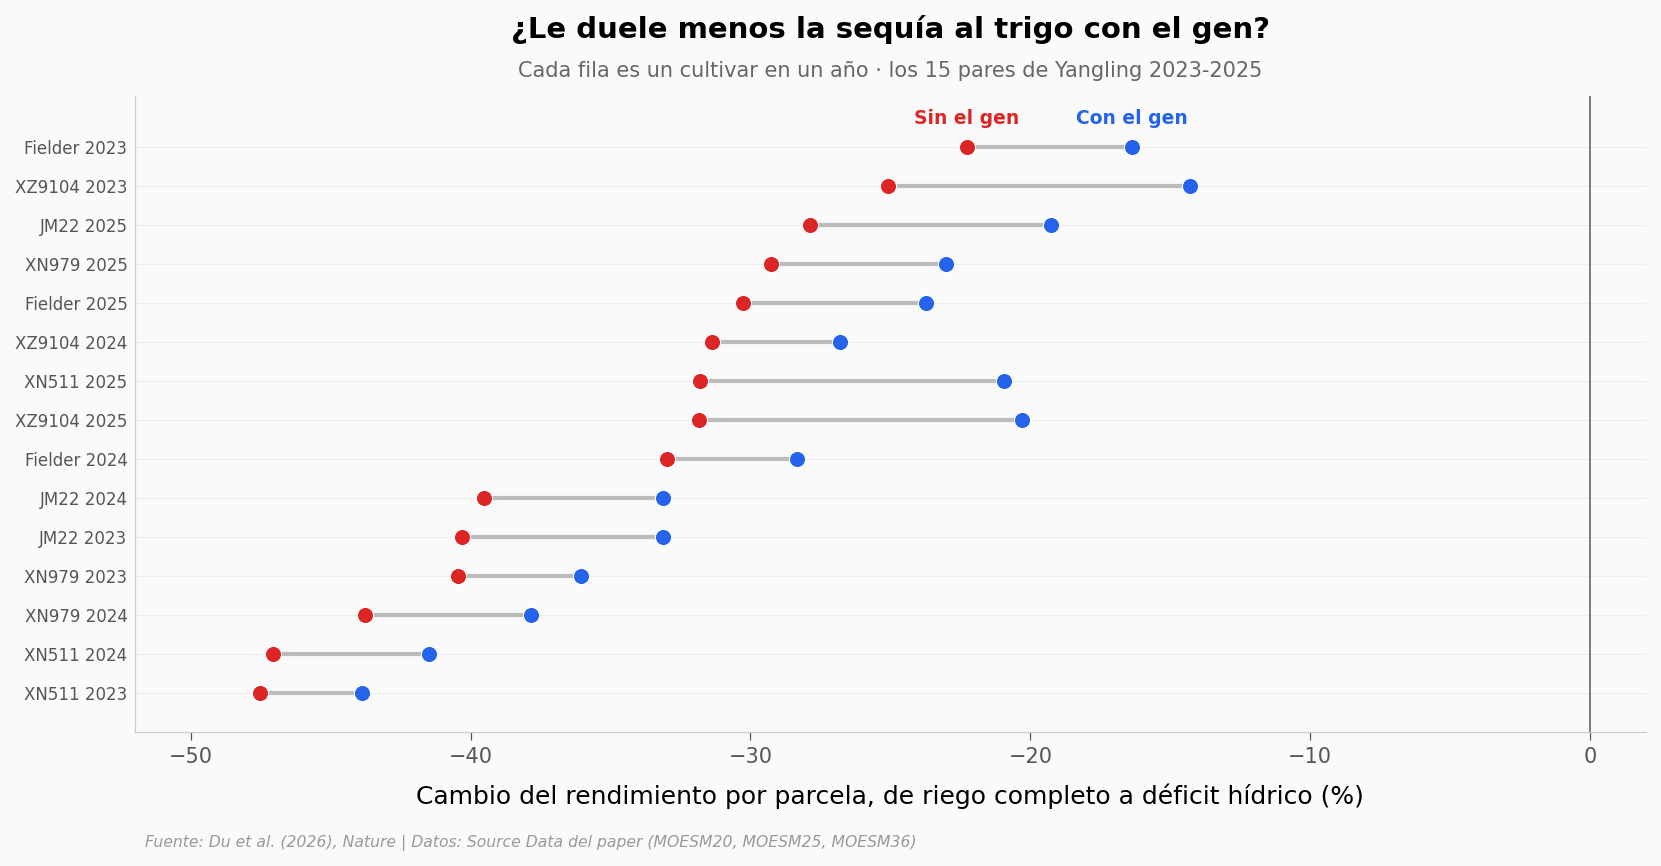

Caída control: mediana −31,8 % (rango −47,5 a −22,3)
Caída con el gen: mediana −26,8 % (rango −43,9 a −14,3)
Pares que pierden menos con el gen: 15/15
Diferencia pareada: mediana 6,2 puntos porcentuales (rango 3,6 a 11,5)
Wilcoxon pareado: p = 6,1×10^−5 | d pareada = 2,74 | n = 15 pares
Con el gen en sequía frente al control con riego completo: mediana −16,9 % (rango −36,6 a −6,2); por debajo en 15/15


In [3]:
p = perd.sort_values('perdida_silvestre_pct').reset_index(drop=True)
y = np.arange(len(p))
fig, ax = plt.subplots(figsize=(13, 5.5))
for yi, a, b in zip(y, p.perdida_silvestre_pct, p.perdida_transgenica_pct):
    ax.plot([a, b], [yi, yi], color=COLOR_GRIS, lw=2, zorder=2)
ax.scatter(p.perdida_silvestre_pct, y, color=COLOR_ALERTA, s=60, edgecolors='white', linewidths=0.5, zorder=5)
ax.scatter(p.perdida_transgenica_pct, y, color=COLOR_DATOS, s=60, edgecolors='white', linewidths=0.5, zorder=5)
ax.set_yticks(y)
ax.set_yticklabels([f'{c} {a}' for c, a in zip(p.cultivar, p.anio)], fontsize=8)
ax.axvline(0, color='#666666', lw=0.8)
ax.text(p.perdida_silvestre_pct.iloc[-1], y[-1] + 0.6, 'Sin el gen', color=COLOR_ALERTA,
        fontsize=9, fontweight='bold', ha='center')
ax.text(p.perdida_transgenica_pct.iloc[-1], y[-1] + 0.6, 'Con el gen', color=COLOR_DATOS,
        fontsize=9, fontweight='bold', ha='center')
ax.set_xlim(-52, 2)
ax.set_ylim(-1, len(p) + 0.3)
ax.set_xlabel('Cambio del rendimiento por parcela, de riego completo a déficit hídrico (%)')
ax.xaxis.set_major_formatter(COMA)
ax.set_title('¿Le duele menos la sequía al trigo con el gen?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Cada fila es un cultivar en un año · los 15 pares de Yangling 2023-2025',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/perdida_por_sequia.png', dpi=200, bbox_inches='tight')
plt.show()

dif = p.perdida_transgenica_pct - p.perdida_silvestre_pct      # positivo = pierde menos con el gen
w = stats.wilcoxon(p.perdida_transgenica_pct, p.perdida_silvestre_pct)
dz = dif.mean() / dif.std(ddof=1)
pr(f'Caída control: mediana {p.perdida_silvestre_pct.median():.1f} % (rango {p.perdida_silvestre_pct.min():.1f} a {p.perdida_silvestre_pct.max():.1f})')
pr(f'Caída con el gen: mediana {p.perdida_transgenica_pct.median():.1f} % (rango {p.perdida_transgenica_pct.min():.1f} a {p.perdida_transgenica_pct.max():.1f})')
pr(f'Pares que pierden menos con el gen: {(dif > 0).sum()}/{len(dif)}')
pr(f'Diferencia pareada: mediana {dif.median():.1f} puntos porcentuales (rango {dif.min():.1f} a {dif.max():.1f})')
pr(f'Wilcoxon pareado: p = {w.pvalue:.1e} | d pareada = {dz:.2f} | n = {len(dif)} pares')
rel = (p.tg_def / p.wt_rie - 1) * 100
pr(f'Con el gen en sequía frente al control con riego completo: mediana {rel.median():.1f} % '
   f'(rango {rel.min():.1f} a {rel.max():.1f}); por debajo en {(rel < 0).sum()}/{len(rel)}')

Los 15 cultivar-año pierden menos con el gen. La caída mediana pasa de −31,8 % en el control a −26,8 % con el gen, y la diferencia pareada mediana es de 6,2 puntos porcentuales (Wilcoxon pareado sobre los 15 pares, p = 6,1×10⁻⁵; d pareada = 2,74).

Pero la sequía sigue costando. El trigo con el gen en sequía rinde una mediana de 16,9 % menos que la variedad original con riego completo, y queda por debajo en los 15 casos. Por eso el abstract dice que el gen desacopla **en parte** (*partially decouples*) el dilema entre resistir la sequía y producir grano: lo afloja, no lo rompe.

¿De dónde sale el grano extra? El paper midió los componentes del rendimiento planta por planta: cuántas espigas, cuántos granos, cuánto pesan.

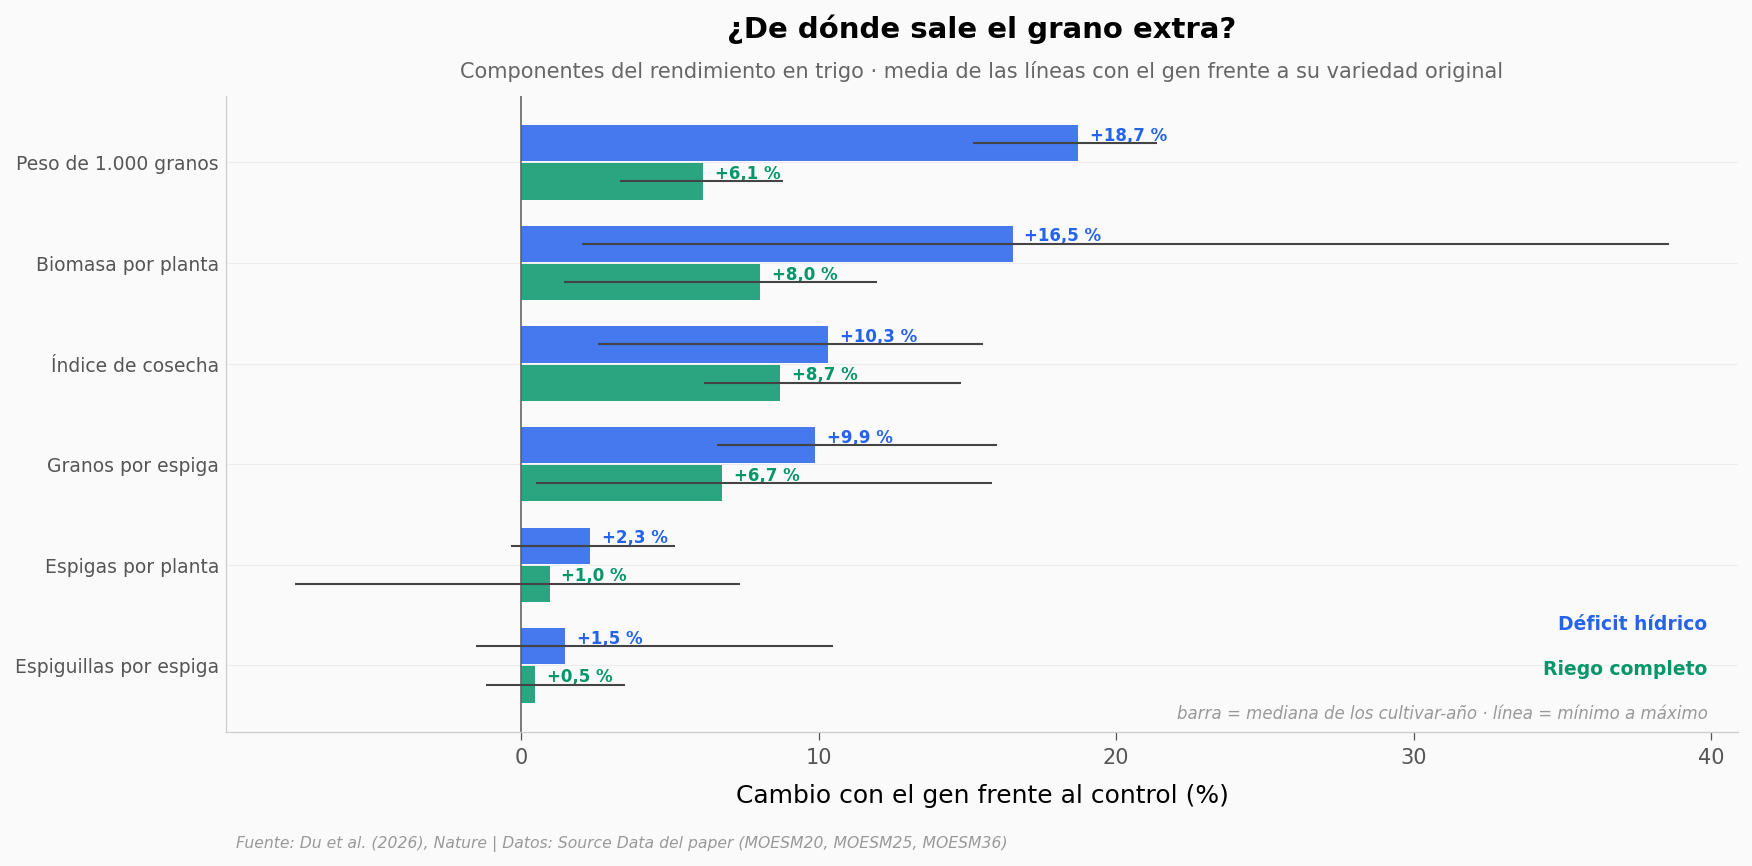

déficit hídrico  Peso de 1.000 granos     mediana +18,7 % | rango +15,2 a +21,4 | n = 15 cultivar-año
déficit hídrico  Biomasa por planta       mediana +16,5 % | rango +2,1 a +38,6 | n = 15 cultivar-año
déficit hídrico  Índice de cosecha        mediana +10,3 % | rango +2,6 a +15,5 | n = 15 cultivar-año
déficit hídrico  Granos por espiga        mediana +9,9 % | rango +6,6 a +16,0 | n = 15 cultivar-año
déficit hídrico  Espigas por planta       mediana +2,3 % | rango −0,3 a +5,2 | n = 10 cultivar-año
déficit hídrico  Espiguillas por espiga   mediana +1,5 % | rango −1,5 a +10,5 | n = 15 cultivar-año
riego completo   Índice de cosecha        mediana +8,7 % | rango +6,2 a +14,8 | n = 15 cultivar-año
riego completo   Biomasa por planta       mediana +8,0 % | rango +1,4 a +12,0 | n = 15 cultivar-año
riego completo   Granos por espiga        mediana +6,7 % | rango +0,5 a +15,8 | n = 15 cultivar-año
riego completo   Peso de 1.000 granos     mediana +6,1 % | rango +3,3 a +8,8 | n = 15 cultivar-añ

In [4]:
RASGOS = {'peso_1000_granos_g': 'Peso de 1.000 granos', 'biomasa_planta_g': 'Biomasa por planta',
          'indice_cosecha': 'Índice de cosecha', 'granos_por_espiga_n': 'Granos por espiga',
          'espigas_n': 'Espigas por planta', 'espiguillas_n': 'Espiguillas por espiga'}
r = ras[ras.rasgo.isin(RASGOS)]
tg = r[r.genotipo == 'transgenico'].groupby(['anio', 'cultivar', 'condicion', 'rasgo'], as_index=False)['media'].mean()
wt = r[r.genotipo == 'silvestre'][['anio', 'cultivar', 'condicion', 'rasgo', 'media']]
comp = tg.merge(wt, on=['anio', 'cultivar', 'condicion', 'rasgo'], suffixes=('_tg', '_wt'))
comp['gan_pct'] = (comp.media_tg / comp.media_wt - 1) * 100
res = comp.groupby(['rasgo', 'condicion']).gan_pct.agg(['median', 'min', 'max', 'count']).reset_index()

orden_r = res[res.condicion == 'deficit_hidrico'].sort_values('median').rasgo.tolist()
fig, ax = plt.subplots(figsize=(13, 5.5))
for k, (c, col, dy) in enumerate([('deficit_hidrico', COLOR_DATOS, 0.19), ('riego_completo', COLOR_SEC, -0.19)]):
    s = res[res.condicion == c].set_index('rasgo').loc[orden_r]
    yy = np.arange(len(orden_r)) + dy
    ax.barh(yy, s['median'], height=0.36, color=col, alpha=0.85, zorder=3)
    ax.hlines(yy, s['min'], s['max'], color='#444444', lw=1, zorder=4)
    for yi, v in zip(yy, s['median']):
        ax.text(max(v, 0) + 0.4, yi + 0.08, f'+{es(f"{v:.1f}")} %', va='center', fontsize=8, color=col, fontweight='bold')
ax.set_yticks(np.arange(len(orden_r)))
ax.set_yticklabels([RASGOS[x] for x in orden_r], fontsize=9)
ax.axvline(0, color='#666666', lw=0.8)
ax.text(0.98, 0.16, 'Déficit hídrico', transform=ax.transAxes, color=COLOR_DATOS, fontsize=9, fontweight='bold', ha='right')
ax.text(0.98, 0.09, 'Riego completo', transform=ax.transAxes, color=COLOR_SEC, fontsize=9, fontweight='bold', ha='right')
ax.text(0.98, 0.02, 'barra = mediana de los cultivar-año · línea = mínimo a máximo', transform=ax.transAxes,
        fontsize=8, color='#999999', ha='right', style='italic')
ax.set_xlabel('Cambio con el gen frente al control (%)')
ax.xaxis.set_major_formatter(COMA)
ax.set_title('¿De dónde sale el grano extra?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Componentes del rendimiento en trigo · media de las líneas con el gen frente a su variedad original',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/componentes_rendimiento.png', dpi=200, bbox_inches='tight')
plt.show()

for _, f in res.sort_values(['condicion', 'median'], ascending=[True, False]).iterrows():
    print(f'{ETQ[f.condicion]:16s} {RASGOS[f.rasgo]:24s}', es(f'mediana {f["median"]:+.1f} % | rango {f["min"]:+.1f} a {f["max"]:+.1f} | n = {f["count"]} cultivar-año'))
ic = comp[(comp.rasgo == 'indice_cosecha') & (comp.condicion == 'deficit_hidrico')].nsmallest(3, 'gan_pct')
pr('Índice de cosecha en déficit, los 3 cultivar-año más bajos:',
   ', '.join(f'{c} {a} ({es(f"{v:.1f}")} %)' for c, a, v in zip(ic.cultivar, ic.anio, ic.gan_pct)))

Con sequía, la pieza que más se mueve es el peso del grano: el peso de 1.000 granos sube una mediana de 18,7 % (de 15,2 % a 21,4 % según cultivar-año, igual que el paper). Le siguen la biomasa por planta (+16,5 %, aunque muy dispersa: de +2,1 % a +38,6 %), el índice de cosecha (+10,3 %) y los granos por espiga (+9,9 %). En cambio, las espigas por planta apenas cambian: +2,3 %, y solo se midieron en 2024 y 2025. Las plantas con el gen no echan muchas más espigas; llenan más granos por espiga y, sobre todo, granos más pesados. Con riego completo, la mediana de cada componente es menor que con sequía.

¿Y fuera del trigo de Yangling? El equipo probó arroz (variedad Nipponbare) en Hanzhong y maíz (línea B73) en tres sitios del noroeste de China, midiendo el rendimiento por planta.

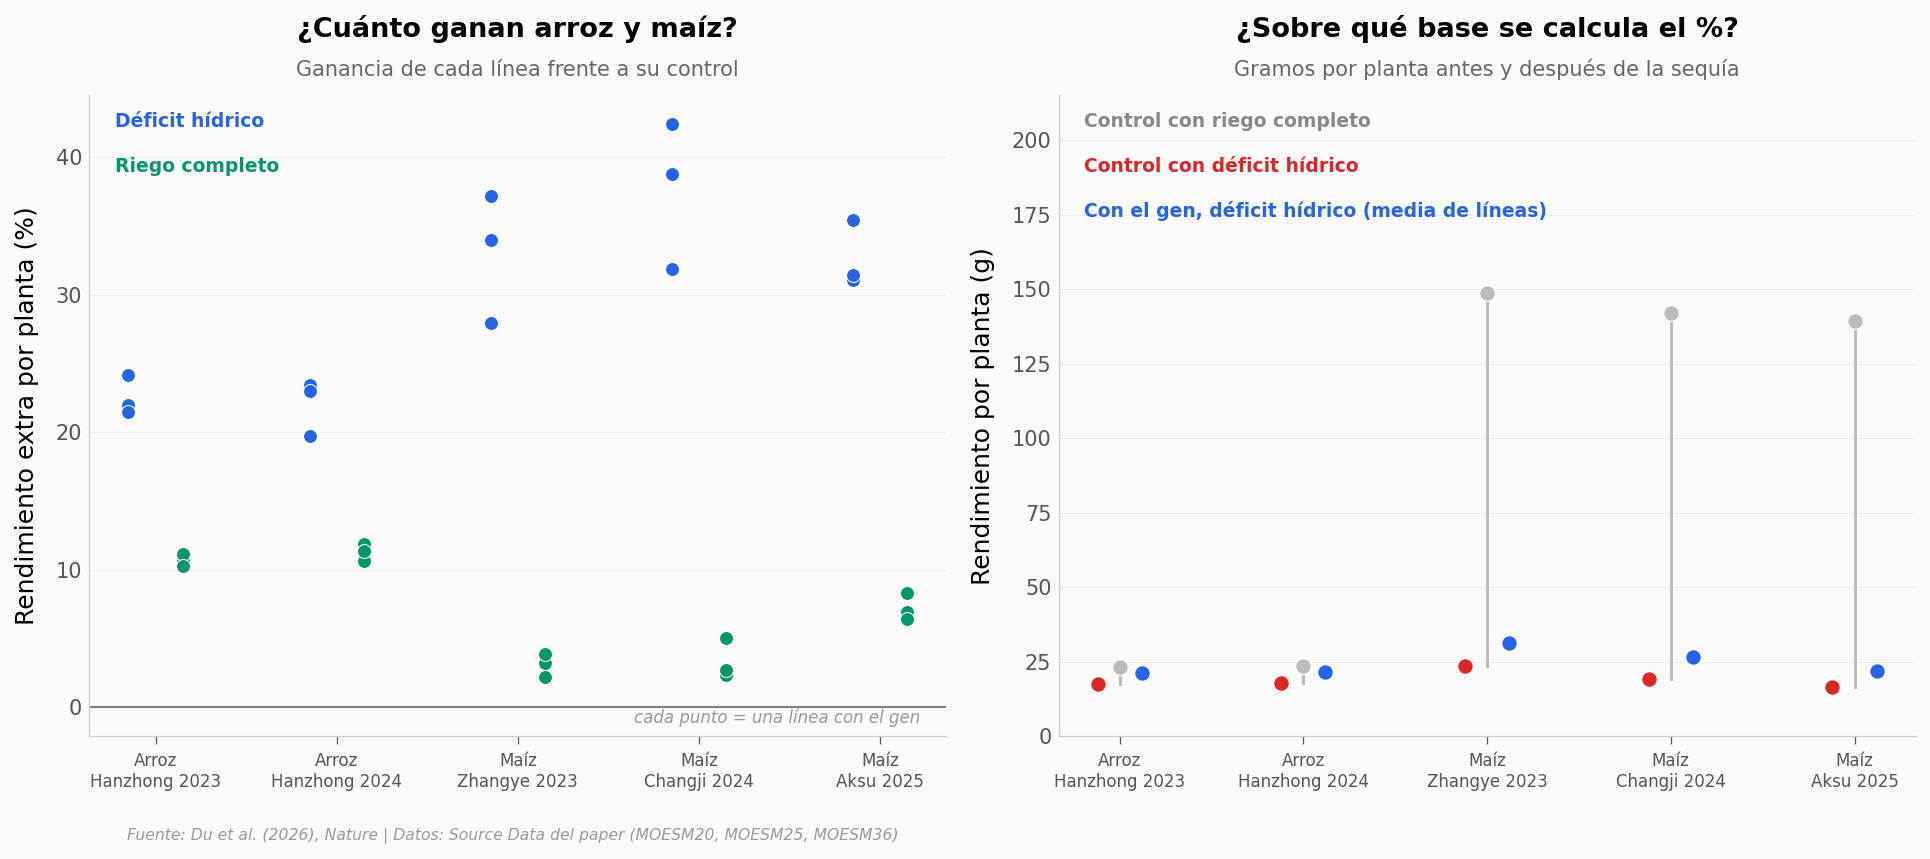

Arroz déficit hídrico  por línea: +19,7 a +24,1 % | +3,5 a +4,2 g/planta | 6 líneas-sitio
Arroz riego completo   por línea: +10,2 a +11,9 % | +2,4 a +2,8 g/planta | 6 líneas-sitio
Maíz  déficit hídrico  por línea: +28,0 a +42,4 % | +5,2 a +8,7 g/planta | 9 líneas-sitio
Maíz  riego completo   por línea: +2,2 a +8,3 % | +3,3 a +11,6 g/planta | 9 líneas-sitio
Arroz déficit hídrico  d de Cohen por línea (planta a planta): 1,74–2,39 | 13–13 plantas por línea
Arroz riego completo   d de Cohen por línea (planta a planta): 0,94–1,90 | 13–13 plantas por línea
Maíz  déficit hídrico  d de Cohen por línea (planta a planta): 1,00–3,77 | 16–35 plantas por línea
Maíz  riego completo   d de Cohen por línea (planta a planta): 0,35–1,40 | 16–35 plantas por línea
Máximo en maíz: Changji 2024, TL43: +42,4 % = +8,2 g sobre 19,3 g del control
Control Arroz Hanzhong 2023: 23,3 → 17,3 g/planta (−25,5 %) | n = 13 plantas por línea
Control Arroz Hanzhong 2024: 23,6 → 17,7 g/planta (−25,0 %) | n = 13 plantas por

In [5]:
grp = ['cultivo', 'sitio', 'anio', 'condicion']
m = am.groupby(grp + ['linea', 'genotipo'], as_index=False).rend_planta_g.mean()
ctl = m[m.genotipo == 'silvestre'][grp + ['rend_planta_g']].rename(columns={'rend_planta_g': 'ctl_g'})
lg = m[m.genotipo == 'transgenico'].merge(ctl, on=grp)
lg['gan_pct'] = (lg.rend_planta_g / lg.ctl_g - 1) * 100
lg['gan_g'] = lg.rend_planta_g - lg.ctl_g
grupos = lg[['cultivo', 'sitio', 'anio']].drop_duplicates().sort_values(['cultivo', 'anio']).reset_index(drop=True)
nombre = {'arroz': 'Arroz', 'maiz': 'Maíz'}
etq = [f'{nombre[c]}\n{s} {a}' for c, s, a in zip(grupos.cultivo, grupos.sitio, grupos.anio)]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
for i, f in grupos.iterrows():
    for c, col, dx in [('deficit_hidrico', COLOR_DATOS, -0.15), ('riego_completo', COLOR_SEC, 0.15)]:
        v = lg[(lg.cultivo == f.cultivo) & (lg.sitio == f.sitio) & (lg.anio == f.anio) & (lg.condicion == c)].gan_pct
        a1.scatter(np.full(len(v), i + dx), v, color=col, s=45, edgecolors='white', linewidths=0.5, zorder=5)
a1.axhline(0, color='#666666', lw=0.8)
a1.set_xticks(range(len(grupos)))
a1.set_xticklabels(etq, fontsize=8)
a1.set_ylabel('Rendimiento extra por planta (%)')
a1.yaxis.set_major_formatter(COMA)
a1.text(0.03, 0.95, 'Déficit hídrico', transform=a1.transAxes, color=COLOR_DATOS, fontsize=9, fontweight='bold')
a1.text(0.03, 0.88, 'Riego completo', transform=a1.transAxes, color=COLOR_SEC, fontsize=9, fontweight='bold')
a1.text(0.97, 0.02, 'cada punto = una línea con el gen', transform=a1.transAxes, fontsize=8,
        color='#999999', ha='right', style='italic')
a1.set_title('¿Cuánto ganan arroz y maíz?', fontsize=13, fontweight='bold', pad=28)
a1.text(0.5, 1.03, 'Ganancia de cada línea frente a su control', transform=a1.transAxes,
        fontsize=10, color='#666666', ha='center')

cm = ctl.merge(grupos, on=['cultivo', 'sitio', 'anio'])
tgm = lg.groupby(grp, as_index=False).rend_planta_g.mean()
for i, f in grupos.iterrows():
    k = (cm.cultivo == f.cultivo) & (cm.sitio == f.sitio) & (cm.anio == f.anio)
    kr = cm[k & (cm.condicion == 'riego_completo')].ctl_g.iloc[0]
    kd = cm[k & (cm.condicion == 'deficit_hidrico')].ctl_g.iloc[0]
    td = tgm[(tgm.cultivo == f.cultivo) & (tgm.sitio == f.sitio) & (tgm.anio == f.anio) & (tgm.condicion == 'deficit_hidrico')].rend_planta_g.iloc[0]
    a2.plot([i, i], [kd, kr], color=COLOR_GRIS, lw=1.5, zorder=2)
    a2.scatter(i, kr, color=COLOR_GRIS, s=55, zorder=5, edgecolors='white')
    a2.scatter(i - 0.12, kd, color=COLOR_ALERTA, s=55, zorder=5, edgecolors='white')
    a2.scatter(i + 0.12, td, color=COLOR_DATOS, s=55, zorder=5, edgecolors='white')
a2.set_xticks(range(len(grupos)))
a2.set_xticklabels(etq, fontsize=8)
a2.set_ylabel('Rendimiento por planta (g)')
a2.yaxis.set_major_formatter(COMA)
a2.text(0.03, 0.95, 'Control con riego completo', transform=a2.transAxes, color='#888888', fontsize=9, fontweight='bold')
a2.text(0.03, 0.88, 'Control con déficit hídrico', transform=a2.transAxes, color=COLOR_ALERTA, fontsize=9, fontweight='bold')
a2.text(0.03, 0.81, 'Con el gen, déficit hídrico (media de líneas)', transform=a2.transAxes, color=COLOR_DATOS, fontsize=9, fontweight='bold')
a2.set_ylim(0, 215)
a2.set_title('¿Sobre qué base se calcula el %?', fontsize=13, fontweight='bold', pad=28)
a2.text(0.5, 1.03, 'Gramos por planta antes y después de la sequía', transform=a2.transAxes,
        fontsize=10, color='#666666', ha='center')
plt.tight_layout()
fig.text(0.07, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/arroz_maiz.png', dpi=200, bbox_inches='tight')
plt.show()

for cult in ['arroz', 'maiz']:
    for c in ['deficit_hidrico', 'riego_completo']:
        s = lg[(lg.cultivo == cult) & (lg.condicion == c)]
        pr(f'{nombre[cult]:5s} {ETQ[c]:16s} por línea: {s.gan_pct.min():+.1f} a {s.gan_pct.max():+.1f} % '
           f'| {s.gan_g.min():+.1f} a {s.gan_g.max():+.1f} g/planta | {len(s)} líneas-sitio')
# d de Cohen por línea entre plantas (descriptivo: las plantas no son réplicas independientes)
def d_coh(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp
dl = []
for (cult, s_, a_, c), sub in am.groupby(['cultivo', 'sitio', 'anio', 'condicion']):
    k = sub[sub.genotipo == 'silvestre'].rend_planta_g
    for linea, sl in sub[sub.genotipo == 'transgenico'].groupby('linea'):
        dl.append((cult, c, d_coh(sl.rend_planta_g, k), len(sl)))
dl = pd.DataFrame(dl, columns=['cultivo', 'condicion', 'd', 'n'])
for (cult, c), sub in dl.groupby(['cultivo', 'condicion']):
    pr(f'{nombre[cult]:5s} {ETQ[c]:16s} d de Cohen por línea (planta a planta): {sub.d.min():.2f}–{sub.d.max():.2f} | {sub.n.min()}–{sub.n.max()} plantas por línea')
top = lg[(lg.cultivo == 'maiz') & (lg.condicion == 'deficit_hidrico')].nlargest(1, 'gan_pct').iloc[0]
pr(f'Máximo en maíz: {top.sitio} {top.anio}, {top.linea}: {top.gan_pct:+.1f} % = {top.gan_g:+.1f} g sobre {top.ctl_g:.1f} g del control')
for (cult, s_, a_), sub in cm.groupby(['cultivo', 'sitio', 'anio']):
    kr = sub[sub.condicion == 'riego_completo'].ctl_g.iloc[0]
    kd = sub[sub.condicion == 'deficit_hidrico'].ctl_g.iloc[0]
    pr(f'Control {nombre[cult]} {s_} {a_}: {kr:.1f} → {kd:.1f} g/planta ({(kd / kr - 1) * 100:.1f} %) '
       f'| n = {am[(am.cultivo == cult) & (am.sitio == s_) & (am.anio == a_)].groupby(["condicion", "linea"]).size().iloc[0]} plantas por línea')

# Trigo en sitios áridos 2025 (secano, sin tratamiento de riego): media de líneas por cultivar y sitio
ma = arid.groupby(['sitio', 'cultivar', 'linea', 'genotipo'], as_index=False).rend_planta_g.mean()
ga = (ma[ma.genotipo == 'transgenico'].groupby(['sitio', 'cultivar']).rend_planta_g.mean()
      / ma[ma.genotipo == 'silvestre'].set_index(['sitio', 'cultivar']).rend_planta_g - 1) * 100
pr(f'Trigo, sitios áridos 2025: {ga.min():.1f}–{ga.max():.1f} % por planta (n = {len(ga)} cultivar-sitio)')
pr('   medianas por sitio:', ', '.join(f'{s} {es(f"{v:.1f}")} %' for s, v in ga.groupby(level=0).median().items()))
pr(f'   Heyang: {ga.loc["Heyang"].min():.1f}–{ga.loc["Heyang"].max():.1f} % | plantas por línea: {arid.groupby(["sitio", "linea", "cultivar"]).size().unique().tolist()}')

En arroz el patrón se parece al del trigo: de 19,7 % a 24,1 % más por planta con déficit hídrico y de 10,2 % a 11,9 % con riego completo, los mismos rangos del paper. En gramos, son de 3,5 a 4,2 g más por planta con sequía. Planta a planta, la d de Cohen por línea va de 1,7 a 2,4 con déficit y de 0,9 a 1,9 con riego completo (13 plantas por línea).

En maíz, el porcentaje con déficit es el más alto del estudio, de 28,0 % a 42,4 %, pero ojo con la base. El maíz control pierde entre 84,3 % y 88,1 % de su rendimiento por planta con déficit: en Changji pasa de 142,0 a 19,3 g. Ese 42,4 % son 8,2 g más sobre 19,3 g. Planta a planta, la diferencia es clara con déficit: la d de Cohen por línea va de 1,0 a 3,8 (de 16 a 35 plantas por línea), frente a 0,35 a 1,40 con riego completo. Es solo descriptiva: las plantas de una misma línea no son réplicas independientes. Con riego completo, el maíz con el gen gana solo entre 2,2 % y 8,3 %, y el propio paper dice que en maíz el rendimiento por planta solo aumentó con déficit hídrico. Así que la frase del abstract «sin importar la disponibilidad de agua» (*regardless of water availability*) encaja con el trigo y el arroz, no con el maíz.

En los tres sitios áridos de 2025, sin tratamiento de riego, el trigo con el gen rindió de 10,9 % a 25,6 % más por planta que su control, según cultivar y sitio.

Falta una pregunta: si miramos planta por planta, ¿qué tan distinto es el trigo con el gen?

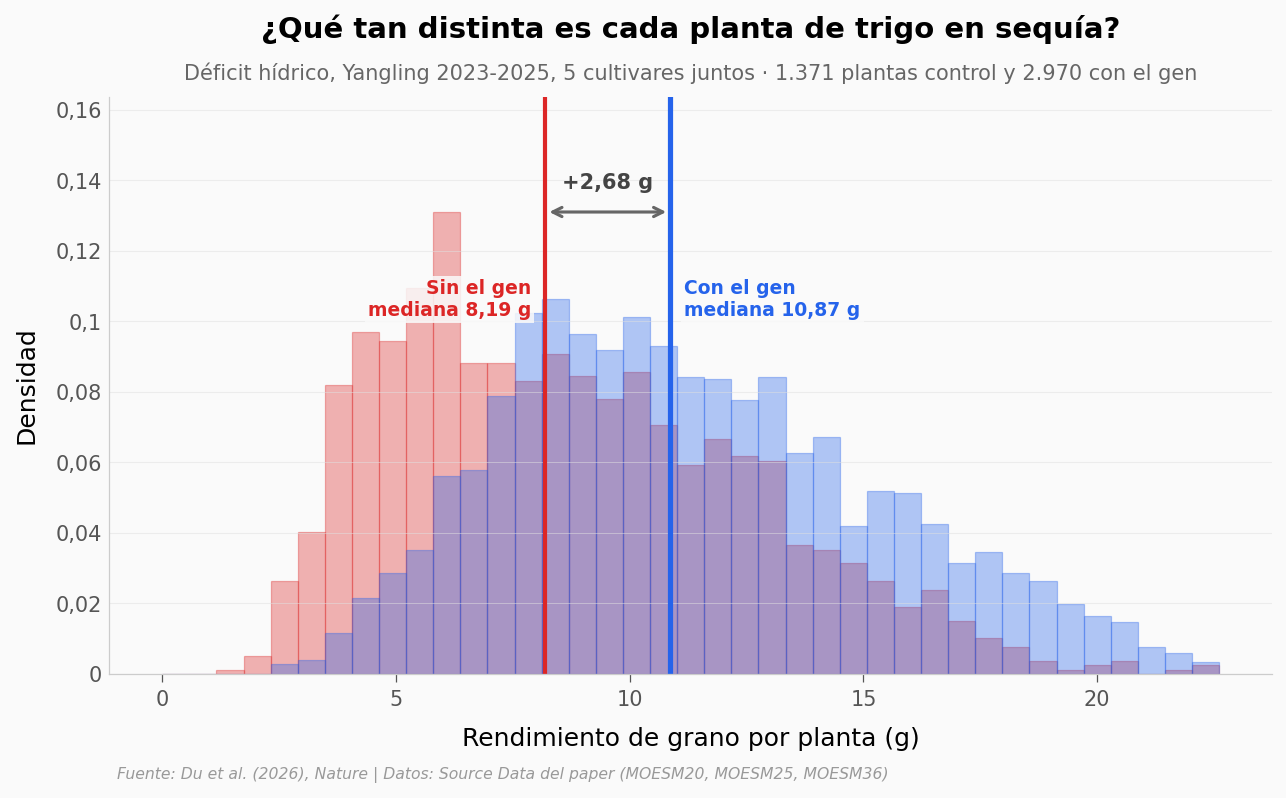

Control     n = 1.371 | mediana 8,19 g | IQR 5,64–11,44 g | asimetría 0,63
Con el gen  n = 2.970 | mediana 10,87 g | IQR 8,34–14,13 g | asimetría 0,52
Ganancia por planta, déficit hídrico: 22,3–38,3 % (n = 15 cultivar-año)
Ganancia por planta, riego completo: 7,6–13,9 % (n = 15 cultivar-año)
Plantas control por encima de la mediana con el gen: 28,2 %
Plantas por línea en Yangling (déficit): 77–100, salidas de 4 parcelas


In [6]:
pd_ = plant[plant.condicion == 'deficit_hidrico']
wtp = pd_[pd_.genotipo == 'silvestre'].rend_planta_g.dropna()
tgp = pd_[pd_.genotipo == 'transgenico'].rend_planta_g.dropna()
bins = np.linspace(0, np.percentile(pd_.rend_planta_g.dropna(), 99.5), 40)

fig, ax = plt.subplots(figsize=(10, 5))
n1, _, _ = ax.hist(wtp, bins=bins, density=True, color=COLOR_ALERTA, alpha=0.35, edgecolor=COLOR_ALERTA, linewidth=0.6)
n2, _, _ = ax.hist(tgp, bins=bins, density=True, color=COLOR_DATOS, alpha=0.35, edgecolor=COLOR_DATOS, linewidth=0.6)
y_max = max(n1.max(), n2.max()) * 1.25
ax.set_ylim(0, y_max)
mw, mt = wtp.median(), tgp.median()
ax.axvline(mw, color=COLOR_ALERTA, lw=2)
ax.axvline(mt, color=COLOR_DATOS, lw=2.5)
ax.annotate('', xy=(mt, y_max * 0.8), xytext=(mw, y_max * 0.8),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text((mw + mt) / 2, y_max * 0.84, f'+{es(f"{mt - mw:.2f}")} g', ha='center', fontsize=10, color='#444444', fontweight='bold')
ax.text(mw - 0.3, y_max * 0.62, f'Sin el gen\nmediana {es(f"{mw:.2f}")} g', color=COLOR_ALERTA, fontsize=9, fontweight='bold', ha='right',
        bbox=dict(facecolor='#FAFAFA', edgecolor='none', alpha=0.85, pad=1.5))
ax.text(mt + 0.3, y_max * 0.62, f'Con el gen\nmediana {es(f"{mt:.2f}")} g', color=COLOR_DATOS, fontsize=9, fontweight='bold', ha='left',
        bbox=dict(facecolor='#FAFAFA', edgecolor='none', alpha=0.85, pad=1.5))
ax.set_xlabel('Rendimiento de grano por planta (g)')
ax.set_ylabel('Densidad')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.set_title('¿Qué tan distinta es cada planta de trigo en sequía?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f'Déficit hídrico, Yangling 2023-2025, 5 cultivares juntos · {len(wtp):_} plantas control y {len(tgp):_} con el gen'.replace('_', '.'),
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/histograma_plantas_sequia.png', dpi=200, bbox_inches='tight')
plt.show()

for nom, s in [('Control', wtp), ('Con el gen', tgp)]:
    q1, q3 = np.percentile(s, [25, 75])
    pr(f'{nom:11s} n = {len(s):_} | mediana {s.median():.2f} g | IQR {q1:.2f}–{q3:.2f} g | asimetría {stats.skew(s):.2f}')
# Ganancia por planta como en el paper: media de líneas con el gen frente al control, por cultivar-año
mp = plant.groupby(['anio', 'cultivar', 'condicion', 'linea', 'genotipo'], as_index=False).rend_planta_g.mean()
gp = (mp[mp.genotipo == 'transgenico'].groupby(['anio', 'cultivar', 'condicion']).rend_planta_g.mean()
      / mp[mp.genotipo == 'silvestre'].set_index(['anio', 'cultivar', 'condicion']).rend_planta_g - 1) * 100
for c in ['deficit_hidrico', 'riego_completo']:
    v = gp.xs(c, level='condicion')
    pr(f'Ganancia por planta, {ETQ[c]}: {v.min():.1f}–{v.max():.1f} % (n = {len(v)} cultivar-año)')
pr(f'Plantas control por encima de la mediana con el gen: {(wtp > mt).mean() * 100:.1f} %')
pr(f'Plantas por línea en Yangling (déficit): {pd_.groupby(["anio", "cultivar", "linea"]).size().min()}–{pd_.groupby(["anio", "cultivar", "linea"]).size().max()}, salidas de 4 parcelas')

Planta a planta, las dos distribuciones se solapan mucho. La mediana con el gen es 10,87 g por planta frente a 8,19 g del control, pero el 28,2 % de las plantas control rinde más que la mediana con el gen. Las dos tienen cola hacia la derecha: unas pocas plantas muy productivas. Aquí juntamos cinco cultivares y tres años, y las plantas no son independientes entre sí, porque salen de solo 4 parcelas por línea. Por eso no calculamos un valor p con ellas: el test honesto es por parcela.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| Con déficit hídrico, el trigo con el gen rinde entre 19,4 % y 32,8 % más por parcela | ✅ | Reproducido exacto con la Source Data. Mediana 21,4 % (IQR 20,6–23,3 %); el 32,8 % es solo XZ9104 en 2025. 33/33 líneas-año por encima del control (Welch p < 0,05 en 33/33 y Mann-Whitney en 32/33 con 4 vs 4 parcelas; d mediana 4,4, inflada por n tan pequeño) |
| Con riego completo, el trigo con el gen rinde entre 7,9 % y 13,6 % más por parcela | ✅ | El paper dice 7,9–13,5 % (redondeo del 13,55 %). Mediana 11,1 %; 33/33 líneas-año por encima del control (Welch p < 0,05 en 33/33 y Mann-Whitney en 31/33) |
| Por planta, la ganancia en trigo es de 22,3 % a 38,3 % con sequía y de 7,6 % a 13,9 % con riego | ✅ | Mismos rangos que el paper. Las plantas son submuestras de 4 parcelas: sirven para describir, no para testear |
| Con el gen, la sequía le cuesta menos al trigo | ✅ | Los 15 cultivar-año pierden menos: mediana −26,8 % frente a −31,8 %, diferencia pareada mediana de 6,2 puntos (Wilcoxon pareado p = 6,1×10⁻⁵, d pareada 2,74) |
| El gen desacopla solo en parte el dilema entre resistir la sequía y producir | ✅ | En sequía, con el gen se rinde una mediana de 16,9 % menos que el control con riego completo, en los 15 casos por debajo. El abstract lo enmarca como *partially decouples* |
| Con sequía, el componente que más sube es el peso del grano | ✅ | Peso de 1.000 granos +18,7 % (15,2–21,4 %, igual que el paper); espigas por planta solo +2,3 % (10 cultivar-año) |
| Arroz: de 19,7 % a 24,1 % más por planta con sequía y de 10,2 % a 11,9 % con riego | ✅ | Mismos rangos que el paper; Hanzhong 2023-2024, 13 plantas por línea |
| Maíz: de 28,0 % a 42,4 % más por planta con sequía | ⚠️ | El dato cuadra con el paper, pero el control pierde 84–88 % con sequía: el 42,4 % son 8,2 g sobre 19,3 g. Con riego completo, solo 2,2–8,3 %, y el paper dice que en maíz el rendimiento solo aumentó con déficit |
| En tres sitios áridos de 2025, el trigo con el gen rindió de 10,9 % a 25,6 % más por planta | ✅ | Mismo rango que el paper. Sin tratamiento de riego y sin parcelas en estos datos: 60 plantas por línea, sin test |
| El gen actúa uniéndose a activadores de la planta, mejora la fotosíntesis y el uso del agua y retrasa el envejecimiento de la hoja | ⚠️ | Lo afirman los autores con otros experimentos; esos datos no están en este notebook |

> **Limitaciones:** (1) La unidad experimental es la parcela, con solo 4 por línea y tratamiento; con n tan pequeño, la d de Cohen sale enorme e inestable. (2) Las 2 o 3 líneas con el gen de cada cultivar comparten el mismo control, así que no son comparaciones independientes. (3) En el índice de cosecha con déficit nuestro rango es 2,6–15,5 % y el del paper 7,6–15,5 %: el 2,6 % es XZ9104 en 2025. (4) No convertimos kg por parcela a toneladas por hectárea: no está verificado qué área se cosechó. (5) Todo se probó en invernadero y campos de China; el paper no trata la regulación ni la adopción de un transgénico.

### Ahora tú

1. **¿Cambia la historia con otro cultivar?** Cambia `CULTIVAR` en la celda de configuración (prueba `'XN511'`, el que más pierde con la sequía) y vuelve a correr la celda de abajo.
2. **¿Qué componente sube más con riego completo?** Pista: `res[res.condicion == 'riego_completo'].sort_values('median')`.
3. **¿En qué año la sequía le costó menos al trigo con el gen?** Pista: `perd.groupby('anio')[['perdida_silvestre_pct', 'perdida_transgenica_pct']].median()`.

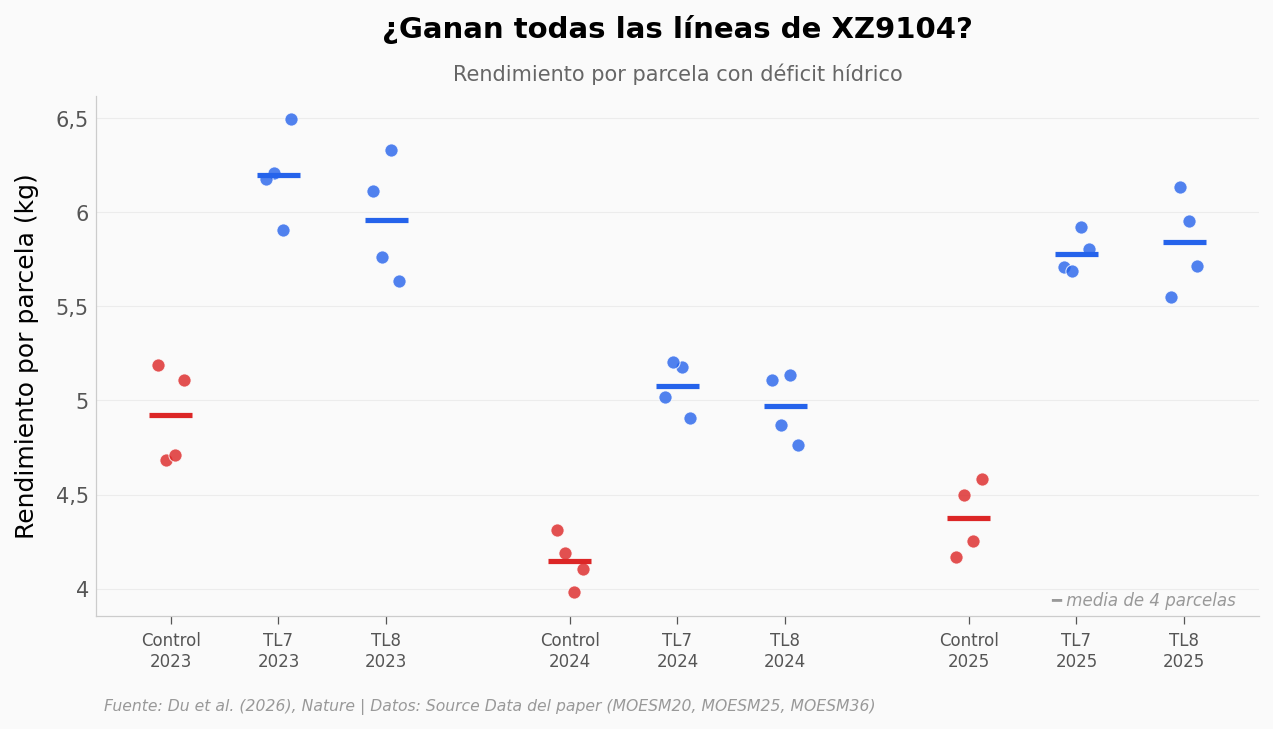

2023 TL7  : +1,27 kg/parcela | d = 5,06 | Welch p = 0,0004 | Mann-Whitney p = 0,0286
2023 TL8  : +1,04 kg/parcela | d = 3,55 | Welch p = 0,0026 | Mann-Whitney p = 0,0286
2024 TL7  : +0,93 kg/parcela | d = 6,66 | Welch p = 0,0001 | Mann-Whitney p = 0,0286
2024 TL8  : +0,82 kg/parcela | d = 5,08 | Welch p = 0,0005 | Mann-Whitney p = 0,0286
2025 TL7  : +1,40 kg/parcela | d = 8,83 | Welch p = 0,0001 | Mann-Whitney p = 0,0286
2025 TL8  : +1,46 kg/parcela | d = 6,36 | Welch p = 0,0001 | Mann-Whitney p = 0,0286


In [7]:
# --- EXPERIMENTA AQUÍ ---
# Parcela por parcela: cada línea con el gen de CULTIVAR frente a su control, en CONDICION
sub = parc[(parc.cultivar == CULTIVAR) & (parc.condicion == CONDICION)]
fig, ax = plt.subplots(figsize=(10, 4.5))
np.random.seed(42)
x0 = 0
ticks, labels = [], []
for anio, sa in sub.groupby('anio'):
    for j, (linea, sl) in enumerate(sorted(sa.groupby('linea'), key=lambda t: t[1].genotipo.iloc[0] != 'silvestre')):
        col = COLOR_ALERTA if sl.genotipo.iloc[0] == 'silvestre' else COLOR_DATOS
        xs = np.linspace(x0 - 0.12, x0 + 0.12, len(sl))
        np.random.shuffle(xs)
        ax.scatter(xs, sl.rend_parcela_kg, color=col, s=40, alpha=0.8, edgecolors='white', linewidths=0.5, zorder=5)
        ax.hlines(sl.rend_parcela_kg.mean(), x0 - 0.2, x0 + 0.2, color=col, lw=2.5, zorder=6)
        ticks.append(x0)
        labels.append(f'{"Control" if col == COLOR_ALERTA else linea}\n{anio}')
        x0 += 1
    x0 += 0.7
ax.set_xticks(ticks)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Rendimiento por parcela (kg)')
ax.yaxis.set_major_formatter(COMA)
ax.text(0.98, 0.02, '━ media de 4 parcelas', transform=ax.transAxes, fontsize=8, color='#999999', ha='right', style='italic')
ax.set_title(f'¿Ganan todas las líneas de {CULTIVAR}?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f'Rendimiento por parcela con {ETQ[CONDICION]}', transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.show()

t = lin[(lin.cultivar == CULTIVAR) & (lin.condicion == CONDICION)].sort_values(['anio', 'linea'])
for _, f in t.iterrows():
    pr(f'{f.anio} {f.linea:5s}: {f.diff_kg:+.2f} kg/parcela | d = {f.d:.2f} | Welch p = {f.p_welch:.4f} | Mann-Whitney p = {f.p_mw:.4f}')

## Créditos

**Paper:** Du et al. (2026). *An extremophile transgene improves drought resistance and yield in cereals*. Nature. DOI: [10.1038/s41586-026-11151-w](https://doi.org/10.1038/s41586-026-11151-w) · Acceso abierto.

**Datos:** Source Data de las Supplementary Tables 1-6 (MOESM20), de la Fig. 5 (MOESM25) y de la Extended Data Fig. 12 (MOESM36), del mismo DOI. Las convertimos a CSV y verificamos que las medias recomputadas coinciden con las Supplementary Tables 1-3 publicadas.

**Repositorio:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab)

## Fuentes

**Paper**: [An extremophile transgene improves drought resistance and yield in cereals](https://doi.org/10.1038/s41586-026-11151-w)  
*Nature, 2026-11-25*

**Supplementary Material**: [Source Data for Supplementary Tables 1–6 (MOESM20) — An extremophile transgene improves drought resistance and yield in cereals](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11151-w/MediaObjects/41586_2026_11151_MOESM20_ESM.zip)  
*Nature, 2026-11-25*

**Supplementary Material**: [Supplementary Tables 1–3: yield-related traits of EpTFIIAγ wheat in Yangling 2023–2025 (MOESM3–5) — An extremophile transgene improves drought resistance and yield in cereals](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11151-w/MediaObjects/41586_2026_11151_MOESM3_ESM.xlsx)  
*Nature, 2026-11-25*

**Supplementary Material**: [Source Data Fig. 5 (MOESM25) — An extremophile transgene improves drought resistance and yield in cereals](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11151-w/MediaObjects/41586_2026_11151_MOESM25_ESM.xlsx)  
*Nature, 2026-11-25*

**Supplementary Material**: [Source Data Extended Data Fig. 12 (MOESM36) — An extremophile transgene improves drought resistance and yield in cereals](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-026-11151-w/MediaObjects/41586_2026_11151_MOESM36_ESM.xlsx)  
*Nature, 2026-11-25*

*20 afirmaciones del notebook verificadas contra estas fuentes*